# Differential equations 7: Fourier series

*Learning path: differential equations, part 7 of 8.* [Index](README.md) · Previous: [Series solutions](06-series-solutions.ipynb) · Next: [Partial differential equations](08-partial-differential-equations.ipynb)

A violin and a flute playing the same note sound different because they mix different amounts of the overtones: twice
the frequency, three times, and so on. Joseph Fourier claimed in 1807 that **every** periodic function, even one with
jumps, is such a mix of sines and cosines. Mathematicians of the day did not believe him; the claim turned out to be
(almost) right and changed mathematics. Fourier needed it to solve the heat equation, which is where the next lesson
uses it. Here we learn to compute the mix and to see how well it converges.

**Who this is for.** You can integrate products like $x\sin nx$ by parts
([foundations 7](../foundations/08-calculus.ipynb)). Lesson 4's `heaviside` and `assume` reappear.

**What you will be able to do afterwards:**

1. compute the Fourier coefficients of a function on $[-L, L]$, using orthogonality, and with `fourier`;
2. use even and odd symmetry to skip half the work, and build half-range sine and cosine series;
3. explain the Gibbs overshoot at a jump, and relate the smoothness of $f$ to how fast its coefficients shrink;
4. sum a numerical series, such as $\sum 1/n^2$, from a Fourier series.

Plan about an hour.

## 1. Orthogonality and the coefficients

On $[-\pi, \pi]$ the functions $1, \cos x, \sin x, \cos 2x, \sin 2x, \ldots$ are **orthogonal**: the integral of the
product of any two different ones is zero. Check a few, and with `assume` the square of $\sin nx$ for every positive
integer $n$ at once:

In [1]:
int(sin(3*x)*cos(5*x), x, -pi, pi)
int(sin(3*x)*sin(5*x), x, -pi, pi)
assume(n, integer, positive)
int(sin(n*x)^2, x, -pi, pi)

0

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

"n > 0, n integer"

> Assumptions now: n > 0, n integer. They decide signs in limits and integrals (e^(-a t) → 0 as t → ∞ when a > 0, sqrt(a²) = a) and simplify sin(nπ) = 0, cos(nπ) = (−1)^n for an integer n. forget(a) removes them.

pi

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

(By hand, $\sin a\cos b = \frac12[\sin(a + b) + \sin(a - b)]$ turns each product into sines that integrate to 0
over a whole period.) So if $f(x) = \frac{a_0}{2} + \sum_{n \ge 1}(a_n\cos nx + b_n\sin nx)$,
multiplying by $\cos nx$ and integrating kills every term but one, and

$$a_n = \frac1\pi\int_{-\pi}^{\pi} f(x)\cos nx\,dx, \qquad b_n = \frac1\pi\int_{-\pi}^{\pi} f(x)\sin nx\,dx.$$

This is the same as finding coordinates in an orthonormal basis
([linear algebra 5](../linear-algebra/05-orthogonality.ipynb)): a dot product with each basis vector. For $f(x) = x$:

In [2]:
int(x*sin(n*x), x, -pi, pi)/pi

-2*(-1)^n/n

$b_n = -2(-1)^n/n = 2(-1)^{n+1}/n$, using $\cos n\pi = (-1)^n$. On an interval $[-L, L]$, replace $nx$ by $n\pi x/L$
and $1/\pi$ by $1/L$. `fourier(f, x, L, N)` computes the series up to the $N$-th harmonic, and its note shows the
general $a_n$ and $b_n$:

In [3]:
fourier(x, x, pi, 4)

2*sin(x)-sin(2*x)+2*sin(3*x)/3-sin(4*x)/2

> Fourier series on [-pi, pi]: f ≈ a0/2 + Σ (a_n cos(n*x) + b_n sin(n*x)), with a_n = (1/pi) ∫ f cos(n*x) dx and b_n = (1/pi) ∫ f sin(n*x) dx over [-pi, pi]. a0 = 0. a_n = 0. b_n = -2*(-1)^n/n. The answer keeps the terms up to n = 4.

**Try this.** Compute the series of $f(x) = x^2$ on $[-\pi, \pi]$ up to $N = 4$. Why are there no sines?

In [4]:
fourier(x^2, x, pi, 4)

pi^2/3-4*cos(x)+cos(2*x)-4*cos(3*x)/9+cos(4*x)/4

> Fourier series on [-pi, pi]: f ≈ a0/2 + Σ (a_n cos(n*x) + b_n sin(n*x)), with a_n = (1/pi) ∫ f cos(n*x) dx and b_n = (1/pi) ∫ f sin(n*x) dx over [-pi, pi]. a0 = 2*pi^2/3. a_n = 4*(-1)^n/n^2. b_n = 0. The answer keeps the terms up to n = 4.

## 2. A square wave and the Gibbs phenomenon

The square wave $f(x) = \operatorname{sign}(x)$ on $[-\pi, \pi]$ is odd, so only sines appear, and the integral splits
at the jump:

$$b_n = \frac2\pi\int_0^\pi \sin nx\,dx = \frac{2(1 - (-1)^n)}{\pi n} = \begin{cases}4/(\pi n) & n \text{ odd}\\ 0 & n \text{ even.}\end{cases}$$

4*sin(x)/pi+4*sin(3*x)/(3*pi)+4*sin(5*x)/(5*pi)

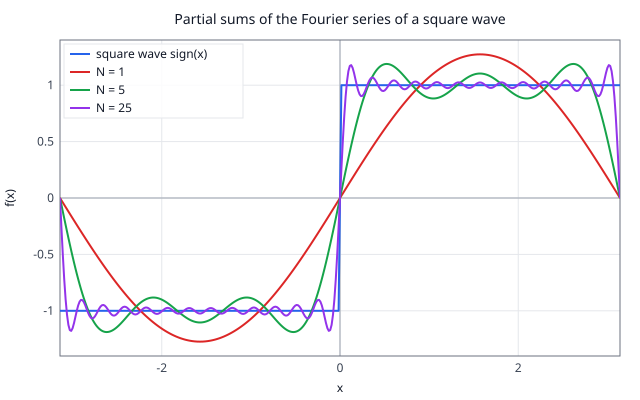

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
s1 = fourier(sign(x), x, pi, 1);
s5 = fourier(sign(x), x, pi, 5);
s25 = fourier(sign(x), x, pi, 25);
s5
p = plot(sign(x), s1, s5, s25, x, -pi, pi);
p = legend(p, "square wave sign(x)", "N = 1", "N = 5", "N = 25");
labels(title(p, "Partial sums of the Fourier series of a square wave"), "x", "f(x)")

The partial sums converge to $\pm1$ away from the jump and to the midpoint $0$ at the jump itself. But near the jump
they **overshoot**, and the overshoot does not shrink as $N$ grows; it only moves closer to the jump. This is the
**Gibbs phenomenon**: the peak tends to about $1.179$, an overshoot of 9% of the jump.

In [6]:
eval(subs(fourier(sign(x), x, pi, 41), x, pi/42))

1.179168757322768

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Audio engineers hear it as "ringing" when a signal with sharp edges is filtered to a limited band of frequencies.

**Try this.** Evaluate the series at $x = \pi/2$: $\frac4\pi(1 - \frac13 + \frac15 - \cdots)$. What famous series for
$\pi/4$ do you get?

## 3. Smoothness and decay

What matters is the **periodic extension** of $f$, repeated with period $2\pi$. The square wave jumps; $x$ jumps
too, from $\pi$ back to $-\pi$; $|x|$ and $x^2$ are continuous but have corners (jumps in the slope). The
coefficients shrink like

* $1/n$ for a function with a jump (square wave, and $x$, whose periodic extension jumps at $\pm\pi$);
* $1/n^2$ for a continuous function with corners ($|x|$, and $x^2$ whose extension has slope jumps at $\pm\pi$).

In [7]:
fourier(abs(x), x, pi, 5)

pi/2-4*cos(x)/pi-4*cos(3*x)/(9*pi)-4*cos(5*x)/(25*pi)

> Fourier series on [-pi, pi]: f ≈ a0/2 + Σ (a_n cos(n*x) + b_n sin(n*x)), with a_n = (1/pi) ∫ f cos(n*x) dx and b_n = (1/pi) ∫ f sin(n*x) dx over [-pi, pi]. a0 = pi. a_n = 2*((-1)^n-1)/(pi*n^2). b_n = 0. The answer keeps the terms up to n = 5.

The faster the coefficients shrink, the faster the series converges and the fewer terms you need: with $1/n^2$
coefficients, three terms of $|x|$ already look like the function. Each extra derivative that is continuous (in the
periodic extension) gives one more power of $n$. This is why smooth periodic signals compress so well.

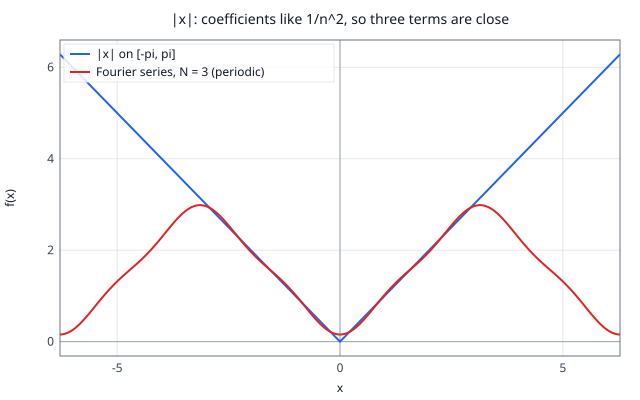

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = plot(abs(x), fourier(abs(x), x, pi, 3), x, -2*pi, 2*pi);
p = legend(p, "|x| on [-pi, pi]", "Fourier series, N = 3 (periodic)");
labels(title(p, "|x|: coefficients like 1/n^2, so three terms are close"), "x", "f(x)")

Outside $[-\pi, \pi]$ the series repeats with period $2\pi$: it represents the **periodic extension** of $f$, a
triangle wave, not $|x|$ itself.

**Try this.** Compute the series of $\text{heaviside}(x)\cdot x$ (zero for $x < 0$, a ramp for $x > 0$). Which
coefficients decay like $1/n$, which like $1/n^2$, and why?

## 4. Half-range series

A function given only on $[0, L]$, such as the initial temperature of a rod, can be extended to $[-L, L]$ in two
natural ways: as an **odd** function (only sines) or as an **even** function (only cosines). The **sine series**

$$f(x) = \sum_{n \ge 1} b_n\sin\frac{n\pi x}{L}, \qquad b_n = \frac2L\int_0^L f(x)\sin\frac{n\pi x}{L}\,dx,$$

vanishes at $x = 0$ and $x = L$; the cosine series has zero slope there. Lesson 8 uses exactly this. For
$f(x) = x(1 - x)$ on $[0, 1]$:

In [9]:
fourier(x*(1 - x), x, 1, 5, "sine")

8*sin(3*pi*x)/(27*pi^3)+8*sin(5*pi*x)/(125*pi^3)+8*sin(pi*x)/pi^3

> Half-range sine series on [0, 1] (f extended as an odd function): f ≈ Σ b_n sin(pi*n*x), with b_n = (2) ∫ f sin(pi*n*x) dx over [0, 1]. b_n = (4-4*(-1)^n)/(pi^3*n^3). The answer keeps the terms up to n = 5.

Only odd $n$ appear, with $b_n = 8/(\pi n)^3$: the function vanishes at both ends and is smooth inside, so the
coefficients shrink like $1/n^3$ and the first term alone is within 3% of $f$.

**Try this.** Compare the sine series and the cosine series of $f(x) = x$ on $[0, \pi]$ with $N = 4$. Which converges
faster, and why? (Think about the extensions: odd extension of $x$ jumps at $\pm\pi$; the even one is $|x|$.)

## 5. Summing series with Fourier

The series of $x^2$ is $\frac{\pi^2}{3} + \sum_{n \ge 1}\frac{4(-1)^n}{n^2}\cos nx$. At $x = \pi$, where
$\cos n\pi = (-1)^n$:

$$\pi^2 = \frac{\pi^2}{3} + 4\sum_{n \ge 1}\frac1{n^2}, \qquad\text{so}\qquad \sum_{n \ge 1}\frac1{n^2} = \frac{\pi^2}{6}.$$

This is Euler's solution of the **Basel problem** (1734), derived in three lines.

In [10]:
sum(1/n^2, n, 1, inf)
forget(n);

pi^2/6

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

**Try this.** Put $x = 0$ in the same series. Which alternating sum do you get?

## Summary

* Sines and cosines are orthogonal on $[-L, L]$, so each coefficient is one integral: $a_n = \frac1L\int f\cos\frac{n\pi x}L$,
  $b_n = \frac1L\int f\sin\frac{n\pi x}L$.
* Odd functions have only sines, even functions only cosines. Half-range series extend a function on $[0, L]$.
* At a jump the series converges to the midpoint and overshoots by about 9% (Gibbs).
* Jumps give coefficients like $1/n$, corners like $1/n^2$; smoother means faster convergence.
* Evaluating a series at a point sums numerical series: $\sum 1/n^2 = \pi^2/6$.

Next: [partial differential equations](08-partial-differential-equations.ipynb), where Fourier series solve the heat
and wave equations.

## Exercises

1. **Sawtooth.** Find the Fourier series of $f(x) = x$ on $[-1, 1]$ by hand and check with `fourier(x, x, 1, 4)`.
2. **Triangle.** Use the series of $|x|$ at $x = 0$ to find $\sum_{k \ge 0}\frac{1}{(2k + 1)^2}$.
3. **Exponential.** Compute `fourier(exp(x), x, pi, 2)`. Why do both sines and cosines appear?
4. **Plucked string.** A string of length 1 is pulled up to height $h$ at its middle: $f(x) = 2hx$ for $x \le 1/2$,
   $2h(1 - x)$ after. Write $f$ with `abs` and find its sine series. Which harmonics are missing?
5. **Parseval.** For the square wave, $\frac1\pi\int_{-\pi}^\pi f^2 = \sum b_n^2$. Use it to find
   $\sum_{k \ge 0}\frac{1}{(2k + 1)^2}$ again.

## Hints and answers

* **Section 1, Try this.** $\frac{\pi^2}3 - 4\cos x + \cos 2x - \frac49\cos 3x + \frac14\cos 4x$. $x^2$ is even,
  and $x^2\sin nx$ is odd, so its integral over $[-\pi, \pi]$ is 0.
* **Section 2, Try this.** $1 = \frac4\pi(1 - \frac13 + \frac15 - \cdots)$: Leibniz's
  $1 - \frac13 + \frac15 - \cdots = \frac\pi4$.
* **Section 3, Try this.** $b_n$ decay like $1/n$ (the periodic extension jumps from $\pi$ to $0$ at $x = \pi$);
  $a_n$ like $1/n^2$ (the corner at $0$).
* **Section 4, Try this.** Sine series $2\sin x - \sin 2x + \ldots$ ($1/n$, the odd extension jumps); cosine series
  $\frac\pi2 - \frac4\pi\cos x - \ldots$ ($1/n^2$, the even extension $|x|$ is continuous). The cosine series wins.
* **Section 5, Try this.** $0 = \frac{\pi^2}3 + 4\sum\frac{(-1)^n}{n^2}$, so
  $1 - \frac14 + \frac19 - \cdots = \frac{\pi^2}{12}$.
* **Exercise 1.** $b_n = 2(-1)^{n+1}/(\pi n)$: $\frac2\pi(\sin\pi x - \frac12\sin 2\pi x + \ldots)$.
* **Exercise 2.** $0 = \frac\pi2 - \frac4\pi\sum\frac{1}{(2k + 1)^2}$, so the sum is $\pi^2/8$.
* **Exercise 3.** $e^x$ is neither even nor odd, and its periodic extension jumps at $\pm\pi$.
* **Exercise 4.** $f = h(1 - 2|x - 1/2|)$; $b_n = \frac{8h}{\pi^2n^2}\sin\frac{n\pi}2$. The even harmonics are
  missing: plucking at the middle cannot excite modes with a node there.
* **Exercise 5.** $\frac1\pi\cdot2\pi = 2 = \sum_{n \text{ odd}}\frac{16}{\pi^2n^2}$, so the sum is $\pi^2/8$.

## Sources

1. J. Fourier, *Théorie analytique de la chaleur*, Firmin Didot (1822).
2. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), sections 10.2 to 10.4.
3. E. Hewitt and R. E. Hewitt, "The Gibbs–Wilbraham phenomenon: an episode in Fourier analysis", *Archive for History
   of Exact Sciences* 21 (1979) 129–160.
4. L. Euler, "De summis serierum reciprocarum", *Commentarii academiae scientiarum Petropolitanae* 7 (1740) 123–134.